In [25]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
import warnings


# População aproximada da França
N = 67_500_000 

# Fonte de dados
URL = "https://raw.githubusercontent.com/CSSEGISandData/COVID-19/master/csse_covid_19_data/csse_covid_19_time_series/time_series_covid19_confirmed_global.csv"

In [26]:
# Ler o CSV
df = pd.read_csv(URL)

# Filtrar França e somar províncias
france_data = df[df['Country/Region'] == 'France'].iloc[:, 4:].sum(axis=0)

# Converter índice para data (com tratamento de erros)
france_data.index = pd.to_datetime(france_data.index, errors='coerce')

# Pegar todos os dados disponíveis
y_real = france_data.values.astype(float)
x_days = np.arange(len(y_real))

print(f"Dados carregados: {len(x_days)} dias de pandemia.")
print(f"Total de infectados acumulados no final: {y_real[-1]:,.0f}")

Dados carregados: 1143 dias de pandemia.
Total de infectados acumulados no final: 39,866,718


In [27]:
def sir_discrete(t, beta, gamma):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    
    # Inicialização
    I[0] = y_real[0] if y_real[0] > 0 else 1.0
    S[0] = N - I[0]
    R[0] = 0.0
    
    # Loop temporal
    for i in range(len(t) - 1):
        # Cálculos do dia
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        
        # Atualização segura
        S[i+1] = max(0, S[i] - new_inf)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = R[i] + new_rec
        
    # Retorna Casos Acumulados (I + R) para o ajuste
    return I + R

In [28]:
def sirs_discrete(t, beta, gamma, xi):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    C = np.zeros(len(t)) # Acumulado
    
    # Inicialização
    C[0] = y_real[0] if y_real[0] > 0 else 1.0
    I[0] = C[0]
    S[0] = N - I[0]
    R[0] = 0.0
    
    for i in range(len(t) - 1):
        new_inf = (beta * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i] # Perda de imunidade
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        C[i+1] = C[i] + new_inf
        
    return C

In [29]:
# Definir número de nós para interpolação do Beta
num_nodes = 5
x_nodes = np.linspace(0, len(x_days), num_nodes)

def sirs_dynamic_discrete(t, gamma, xi, *betas_array):
    
    S = np.zeros(len(t))
    I = np.zeros(len(t))
    R = np.zeros(len(t))
    C = np.zeros(len(t))
    
    C[0] = y_real[0] if y_real[0] > 0 else 1.0
    I[0] = C[0]
    S[0] = N - I[0]
    R[0] = 0.0
    
    for i in range(len(t) - 1):
        # Descobre qual o Beta do dia atual (interpolação)
        beta_t = np.interp(i, x_nodes, betas_array)
        
        new_inf = (beta_t * S[i] * I[i]) / N
        new_rec = gamma * I[i]
        new_susc = xi * R[i]
        
        S[i+1] = max(0, S[i] - new_inf + new_susc)
        I[i+1] = max(0, I[i] + new_inf - new_rec)
        R[i+1] = max(0, R[i] + new_rec - new_susc)
        C[i+1] = C[i] + new_inf
        
    return C

Iniciando otimização (aguarde alguns segundos)...


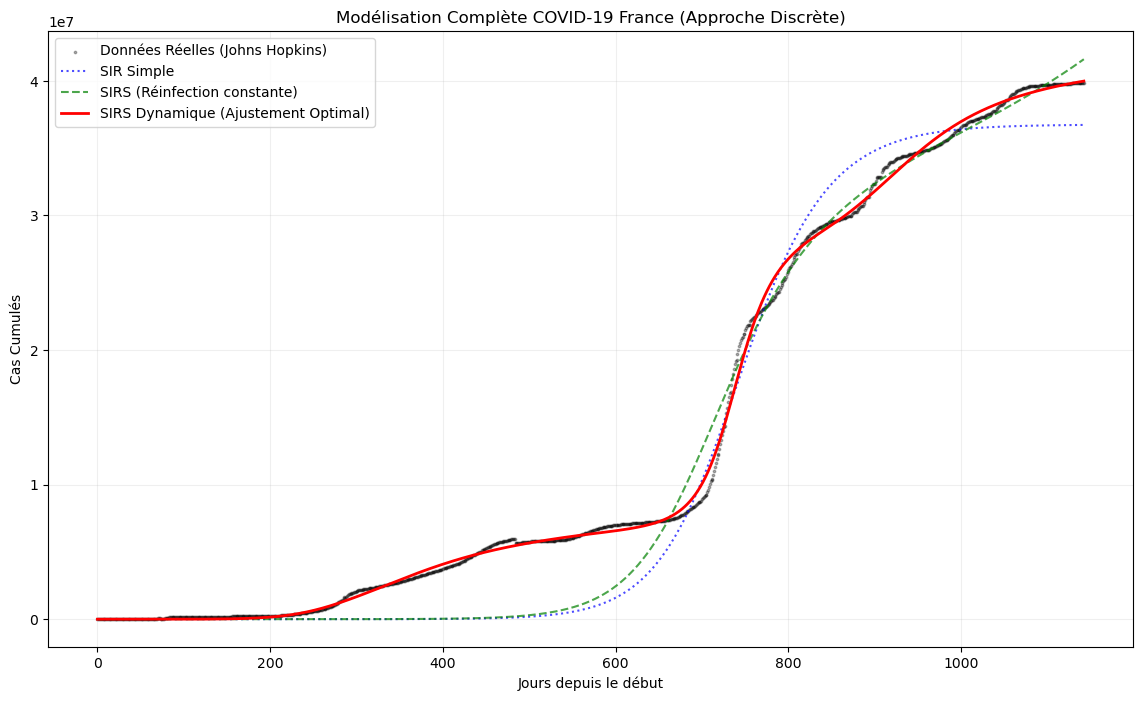

--- Résultats ---
SIR Simple -> Beta: 0.0722, Gamma: 0.0501
SIRS -> Xi (Perte d'immunité): 0.00483
Dynamique -> R0 Moyen: 1.13


In [18]:
print("Iniciando otimização (aguarde alguns segundos)...")

# --- 1. Ajuste SIR ---
# Limites: Beta [0, 5], Gamma [0, 1]
popt_sir, _ = curve_fit(sir_discrete, x_days, y_real, p0=[0.1, 0.05], bounds=(0, [5.0, 1.0]))

# --- 2. Ajuste SIRS ---
# Limites: Beta [0, 5], Gamma [0, 1], Xi [0, 1]
popt_sirs, _ = curve_fit(sirs_discrete, x_days, y_real, p0=[0.1, 0.05, 0.001], bounds=(0, [5.0, 1.0, 1.0]))

# --- 3. Ajuste Dinâmico ---
# Prepara limites e chutes iniciais para todos os betas
initial_guess = [0.05, 0.001] + [0.15] * num_nodes # Gamma, Xi, Betas...
lower_bounds = [0.0, 0.0] + [0.0] * num_nodes
upper_bounds = [1.0, 1.0] + [5.0] * num_nodes

popt_dyn, _ = curve_fit(sirs_dynamic_discrete, x_days, y_real, 
                        p0=initial_guess, 
                        bounds=(lower_bounds, upper_bounds),
                        maxfev=10000) # Aumenta o limite de tentativas

# --- Gerar Curvas Finais ---
y_pred_sir = sir_discrete(x_days, *popt_sir)
y_pred_sirs = sirs_discrete(x_days, *popt_sirs)
y_pred_dyn = sirs_dynamic_discrete(x_days, *popt_dyn)

# --- Gráfico ---
plt.figure(figsize=(14, 8))

# Dados Reais
plt.scatter(x_days, y_real, label="Données Réelles (Johns Hopkins)", color='black', s=3, alpha=0.3)

# Modelos
plt.plot(x_days, y_pred_sir, label="SIR Simple", linestyle=':', color='blue', alpha=0.7)
plt.plot(x_days, y_pred_sirs, label="SIRS (Réinfection constante)", linestyle='--', color='green', alpha=0.7)
plt.plot(x_days, y_pred_dyn, label="SIRS Dynamique (Ajustement Optimal)", color='red', linewidth=2)

plt.title("Modélisation Complète COVID-19 France (Approche Discrète)")
plt.xlabel("Jours depuis le début")
plt.ylabel("Cas Cumulés")
plt.legend()
plt.grid(True, alpha=0.2)
plt.show()

# --- Resultados Numéricos ---
print("--- Résultats ---")
print(f"SIR Simple -> Beta: {popt_sir[0]:.4f}, Gamma: {popt_sir[1]:.4f}")
print(f"SIRS -> Xi (Perte d'immunité): {popt_sirs[2]:.5f}")
print(f"Dynamique -> R0 Moyen: {(np.mean(popt_dyn[2:]) / popt_dyn[0]):.2f}")